In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files
uploaded = files.upload()

import io

filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")

Saving customer-churn-training.csv to customer-churn-training.csv
Dataset loaded successfully!


In [4]:
# Display first five rows
print("First five rows:")
display(df.head())

# Display dataset shape
print("Dataset shape:", df.shape)

# Display column information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

First five rows:


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


Dataset shape: (12, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        12 non-null     object
 1   tenure_months      12 non-null     int64 
 2   support_tickets    12 non-null     int64 
 3   monthly_spend_inr  12 non-null     int64 
 4   last_login_days    12 non-null     int64 
 5   plan_type          12 non-null     object
 6   churned            12 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 804.0+ bytes

Statistical Summary:


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
count,12,12.000000,12.000000,12.000000,12.000000,12,12.000000
unique,12,NaN,NaN,NaN,NaN,3,NaN
top,C001,NaN,NaN,NaN,NaN,Basic,NaN
freq,1,NaN,NaN,NaN,NaN,5,NaN
mean,NaN,12.166667,2.250000,915.666667,10.000000,NaN,0.416667
std,NaN,9.242524,1.602555,332.574895,9.095453,NaN,0.514929
min,NaN,1.000000,0.000000,499.000000,1.000000,NaN,0.000000
25%,NaN,5.500000,1.000000,724.000000,2.750000,NaN,0.000000
50%,NaN,9.500000,2.000000,899.000000,7.000000,NaN,0.000000
75%,NaN,18.500000,3.250000,1074.000000,14.750000,NaN,1.000000


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check unique customer IDs
print("\nUnique Customer IDs:")
print(df["customer_id"].nunique())

Missing Values:
customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

Duplicate Records:
0

Unique Customer IDs:
12


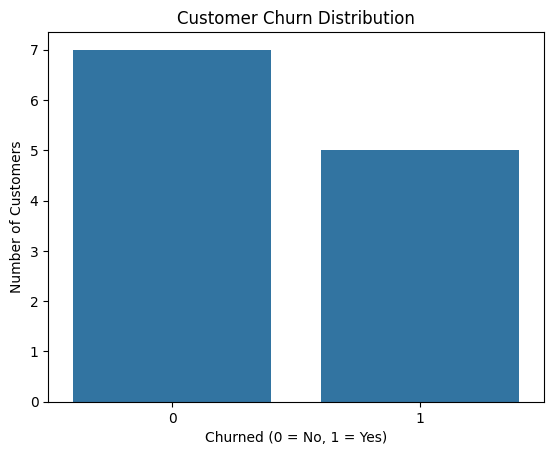

In [6]:
# Count customers in each churn category

sns.countplot(data=df, x="churned")

plt.title("Customer Churn Distribution")
plt.xlabel("Churned (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

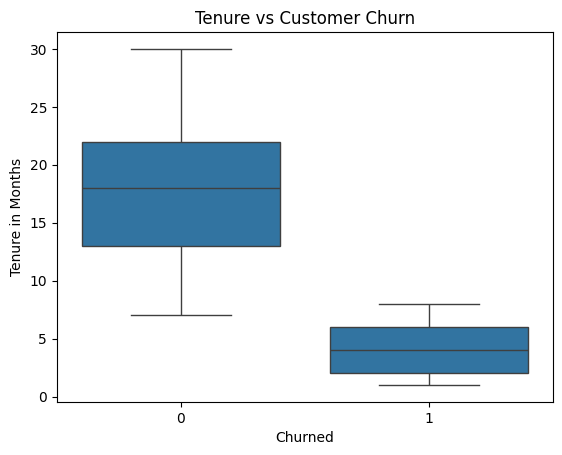

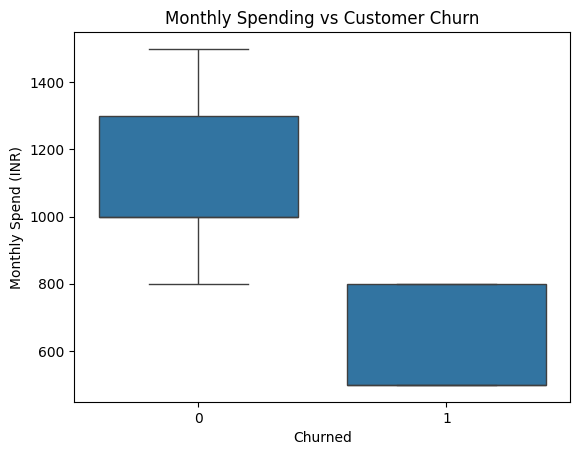

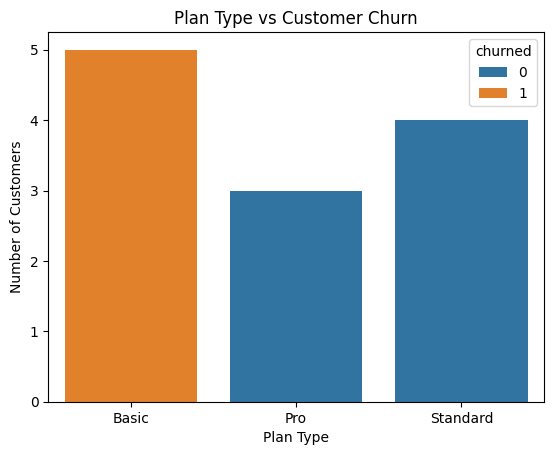

In [7]:
# Tenure vs Churn

sns.boxplot(data=df, x="churned", y="tenure_months")

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churned")
plt.ylabel("Tenure in Months")

plt.show()

# Monthly Spending vs Churn

sns.boxplot(data=df, x="churned", y="monthly_spend_inr")

plt.title("Monthly Spending vs Customer Churn")
plt.xlabel("Churned")
plt.ylabel("Monthly Spend (INR)")

plt.show()

# Plan Type vs Churn

sns.countplot(data=df, x="plan_type", hue="churned")

plt.title("Plan Type vs Customer Churn")
plt.xlabel("Plan Type")
plt.ylabel("Number of Customers")

plt.show()

In [8]:
# Remove customer ID from input features

X = df.drop(columns=["customer_id", "churned"])

# Target variable
y = df["churned"]

print("Input Features:")
display(X.head())

print("Target Variable:")
display(y.head())

Input Features:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type
0,2,4,499,21,Basic
1,18,1,1299,2,Pro
2,6,3,799,14,Basic
3,30,0,1499,1,Pro
4,11,2,999,5,Standard


Target Variable:


,churned
0,1
1,0
2,1
3,0
4,0


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 9
Testing records: 3


In [10]:
# Identify numerical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days']
Categorical Features: ['plan_type']


In [11]:
# Numerical preprocessing

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Numerical and categorical preprocessing created!")

Numerical and categorical preprocessing created!


In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [13]:
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Machine Learning Pipeline created!")

Machine Learning Pipeline created!


In [14]:
model_pipeline.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [15]:
y_pred = model_pipeline.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
[1 0 0]

Predicted Values:
[1 0 0]


In [16]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

MODEL EVALUATION RESULTS
------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


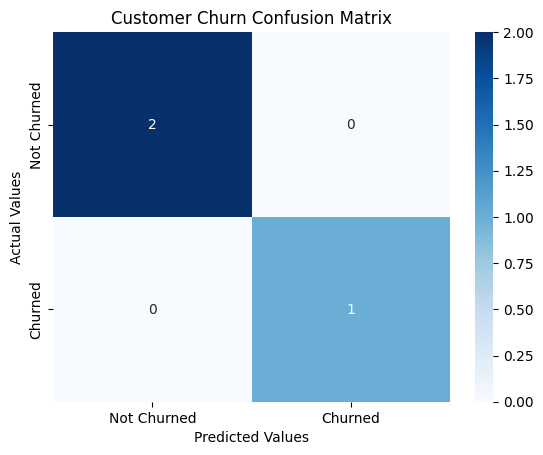

In [17]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.title("Customer Churn Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [18]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Churned", "Churned"],
    zero_division=0
))

              precision    recall  f1-score   support

 Not Churned       1.00      1.00      1.00         2
     Churned       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [19]:
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 1.0


In [20]:
# Get transformed feature names

feature_names = model_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get model coefficients

coefficients = model_pipeline.named_steps[
    "classifier"
].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

display(feature_importance)

,Feature,Coefficient,Absolute Importance
3,num__last_login_days,0.659267,0.659267
1,num__support_tickets,0.596604,0.596604
2,num__monthly_spend_inr,-0.574555,0.574555
4,cat__plan_type_Basic,0.498936,0.498936
0,num__tenure_months,-0.497930,0.497930
6,cat__plan_type_Standard,-0.291302,0.291302
5,cat__plan_type_Pro,-0.208231,0.208231


In [21]:
results = X_test.copy()

results["Actual Churn"] = y_test
results["Predicted Churn"] = y_pred

results["Churn Probability"] = y_prob

display(results)

,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,Actual Churn,Predicted Churn,Churn Probability
9,4,3,499,12,Basic,1,1,0.836584
11,7,2,799,9,Standard,0,0,0.401973
6,24,1,999,3,Standard,0,0,0.079054
